# EDA on our clean sales data

In [2]:
import json
import pandas as pd
from sales import generate_month

products = pd.DataFrame({
    "product_id": [f"PRD-{10001 + i}" for i in range(10)],
    "price_sek": [199.0, 149.0, 349.0, 99.0, 49.0, 599.0, 999.0, 129.0, 399.0, 499.0,]
})

products

,product_id,price_sek
0,PRD-10001,199.0
1,PRD-10002,149.0
2,PRD-10003,349.0
3,PRD-10004,99.0
4,PRD-10005,49.0
5,PRD-10006,599.0
6,PRD-10007,999.0
7,PRD-10008,129.0
8,PRD-10009,399.0
9,PRD-10010,499.0


In [3]:
sales_data = generate_month(products, 2026, 10)
print(f"{len(sales_data)} sales_data")

1291 sales_data


In [4]:
print(json.dumps(sales_data[0], indent=2, ensure_ascii=False, default=str))

{
  "transaction_id": "TXN-2026-10-01-000001",
  "transaction_timestamp": "2026-10-01T10:02:07+02:00",
  "transaction_type": "sale",
  "store_id": "STO-001",
  "register_id": "KASSA-01",
  "employee_id": "EMP-0512",
  "customer_id": null,
  "items": [
    {
      "line_number": 1,
      "product_id": "PRD-10001",
      "quantity": 2,
      "unit_price": 199.0,
      "discount_amount": 0.0,
      "vat_rate": 0.25,
      "line_total": 398.0
    },
    {
      "line_number": 2,
      "product_id": "PRD-10010",
      "quantity": 1,
      "unit_price": 499.0,
      "discount_amount": 0.0,
      "vat_rate": 0.25,
      "line_total": 499.0
    },
    {
      "line_number": 3,
      "product_id": "PRD-10009",
      "quantity": 3,
      "unit_price": 399.0,
      "discount_amount": 0.0,
      "vat_rate": 0.25,
      "line_total": 1197.0
    }
  ],
  "campaign_code": null,
  "payment_method": "card",
  "currency": "SEK",
  "subtotal": 2094.0,
  "total_discount": 0.0,
  "vat_amount": 418.8,
  "to

In [5]:
receipts = pd.json_normalize(sales_data).drop(columns="items")
lines = pd.json_normalize(
    sales_data,
    record_path="items",
    meta=["transaction_id", "transaction_timestamp", "transaction_type"],
)

money_cols = ["subtotal", "total_discount", "vat_amount", "total_amount"]
receipts[money_cols] = receipts[money_cols].astype(float)
line_money_cols = ["unit_price", "discount_amount", "line_total"]
lines[line_money_cols] = lines[line_money_cols].astype(float)

receipts.head()

,transaction_id,transaction_timestamp,transaction_type,store_id,register_id,employee_id,customer_id,campaign_code,payment_method,currency,subtotal,total_discount,vat_amount,total_amount
0,TXN-2026-10-01-000001,2026-10-01T10:02:07+02:00,sale,STO-001,KASSA-01,EMP-0512,NaN,NaN,card,SEK,2094.0,0.0,418.80,2094.0
1,TXN-2026-10-01-000002,2026-10-01T10:18:28+02:00,sale,STO-001,KASSA-01,EMP-0102,NaN,NaN,card,SEK,4940.0,0.0,988.00,4940.0
2,TXN-2026-10-01-000003,2026-10-01T10:20:17+02:00,sale,STO-001,KASSA-01,EMP-0215,CUST-66884,HOST10,card,SEK,258.0,25.8,46.44,232.2
3,TXN-2026-10-01-000004,2026-10-01T10:36:12+02:00,sale,STO-001,KASSA-03,EMP-0457,NaN,NaN,card,SEK,485.0,0.0,97.00,485.0
4,TXN-2026-10-01-000005,2026-10-01T10:48:49+02:00,sale,STO-001,KASSA-01,EMP-0215,NaN,HOST10,card,SEK,1626.0,162.6,292.68,1463.4


In [6]:
diff = (receipts["subtotal"] - receipts["total_discount"] - receipts["total_amount"]).abs()
line_sums = lines.groupby("transaction_id")["line_total"].sum()
line_diff = (receipts.set_index("transaction_id")["total_amount"] - line_sums).abs()

print("Unique transaction_id:", receipts["transaction_id"].is_unique)
print("Totals match:", (diff < 0.01).all())
print("Line totals match:", (line_diff < 0.01).all())
print("\nTransaction types:\n", receipts["transaction_type"].value_counts(normalize=True).round(3))
print("\nPayment methods:\n", receipts["payment_method"].value_counts(normalize=True).round(3))
print("\nMember share:", round(receipts["customer_id"].notna().mean(), 3))
print("\nCampaigns:\n", receipts["campaign_code"].value_counts(dropna=False))
print("\nTimezones:\n", receipts["transaction_timestamp"].str[-6:].value_counts())

Unique transaction_id: True
Totals match: True
Line totals match: True

Transaction types:
 transaction_type
sale      0.976
return    0.024
Name: proportion, dtype: float64

Payment methods:
 payment_method
card     0.725
swish    0.234
cash     0.041
Name: proportion, dtype: float64

Member share: 0.392

Campaigns:
 campaign_code
NaN       1100
HOST10     191
Name: count, dtype: int64

Timezones:
 transaction_timestamp
+02:00    1002
+01:00     289
Name: count, dtype: int64


<Axes: title={'center': 'Transactions per day'}, xlabel='date'>

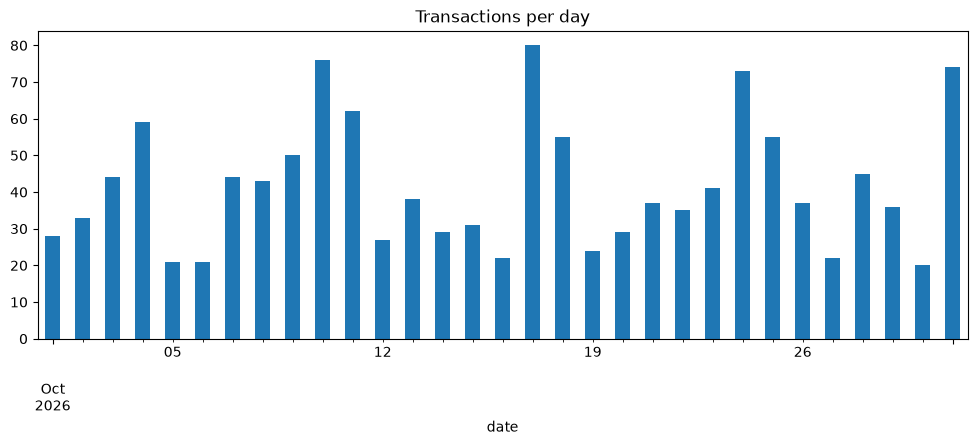

In [7]:
from matplotlib import pyplot as plt 

receipts["date"] = pd.to_datetime(receipts["transaction_timestamp"].str[:10])
receipts.groupby("date").size().plot(kind="bar", figsize=(12, 4), title="Transactions per day")

In [8]:
lines.groupby("product_id")["quantity"].sum().sort_values(ascending=False)

product_id
PRD-10003    691
PRD-10005    651
PRD-10009    651
PRD-10001    624
PRD-10008    621
PRD-10006    616
PRD-10004    600
PRD-10010    596
PRD-10007    591
PRD-10002    572
Name: quantity, dtype: int64